# 3. Test results, figures and dashboard export
Run this after notebook 02. Models and thresholds are already fixed. This notebook evaluates the later test records, draws two clear results charts and saves the dashboard data.

Precision asks how many alerts were scams; recall asks how many scams were caught. F1 balances those two measures. False positive rate asks how many legitimate vouchers were incorrectly flagged. None is proof of real-world bank performance.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "config/generator.yaml").exists(), "Open this notebook from the Research repository."
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import yaml
from IPython.display import display
CONFIG = yaml.safe_load((ROOT / "config/generator.yaml").read_text())
OUT = ROOT / "report/core"
TABLES, FIGURES = OUT / "tables", OUT / "figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

In [2]:
import joblib
import json
import matplotlib.pyplot as plt
from core_evaluation import load_data, split_stage, check_fitted_bundle, metrics, scenario_rates, risk_bands, save_figure
from models import rule_score, hybrid_score
bundle = joblib.load(OUT / "models/fitted_models.joblib")
check_fitted_bundle(bundle, ROOT)
df = load_data(ROOT)
metric_rows, scenario_tables, scored_parts = [], [], []
metadata = {"fingerprint": bundle["fingerprint"], "protocol": bundle["protocol"], "stages": {}}
for stage in ("A", "B"):
    _, _, test = split_stage(df, stage, CONFIG["start_date"])
    selected = bundle["stages"][stage]
    rules, reasons = rule_score(test, stage)
    scores = {"Rules": rules}
    scores.update({name: scorer.score(test) for name, scorer in selected["scorers"].items()})
    anomaly = selected["hybrid_anomaly"]
    scores["Hybrid"] = hybrid_score(rules, scores[anomaly], selected["hybrid_weight"])
    predictions = {}
    for name, values in scores.items():
        threshold = selected["thresholds"][name]
        metric_rows.append({"stage": stage, "model": name, "hybrid_anomaly": anomaly if name == "Hybrid" else "", **metrics(test.is_scam, values, threshold)})
        predictions[name] = values >= threshold
    scenario_tables.append(scenario_rates(test, predictions, stage))
    output = test[["voucher_id", "customer_id", "created_at", "redeemed_at", "score_time", "amount", "scenario_type", "is_scam"]].copy()
    output["stage"] = stage
    output["risk"] = 100 * scores["Hybrid"]
    output["alert"] = predictions["Hybrid"]
    output["band"] = risk_bands(scores["Hybrid"], selected["band_cutoffs"])
    output["rule_indicators"] = [" | ".join(r) for r in reasons]
    assert np.array_equal(output.alert, output.band.isin(["High", "Critical"])), "Band and alert decisions disagree"
    scored_parts.append(output)
    metadata["stages"][stage] = {"model": f"Rules + {anomaly}", "hybrid_weight": selected["hybrid_weight"],
        "cutoffs": {k: 100*v for k,v in selected["band_cutoffs"].items()}, "settings": selected["settings"],
        "thresholds": selected["thresholds"]}
results = pd.DataFrame(metric_rows)
scenarios = pd.concat(scenario_tables, ignore_index=True)
results.to_csv(TABLES / "model_comparison.csv", index=False)
scenarios.to_csv(TABLES / "scenario_detection.csv", index=False)
counts = results[results.model == "Hybrid"][["stage", "hybrid_anomaly", "tp", "fp", "fn", "tn"]]
counts.to_csv(TABLES / "hybrid_decisions.csv", index=False)
scored = pd.concat(scored_parts, ignore_index=True)
scored.to_csv(ROOT / "data/synthetic/core_scored_vouchers.csv", index=False)
metadata["start_date"] = CONFIG["start_date"]
(ROOT / "data/synthetic/core_dashboard_meta.json").write_text(json.dumps(metadata, indent=2))
from importlib.metadata import version
import platform
metadata["software"] = {p: version(p) for p in ("numpy", "pandas", "scikit-learn", "matplotlib", "nbformat", "nbclient", "streamlit")}
metadata["software"]["python"] = platform.python_version()
metadata["fitted_at"] = bundle["created_at"]
(OUT / "run_metadata.json").write_text(json.dumps({**metadata, "model_seed": bundle["model_seed"], "simulator_seed": bundle["simulator_seed"]}, indent=2))

1927

## Compare the five approaches
These are all test results at validation-selected thresholds. A higher F1 does not mean every individual metric improved. Look at false alarms as well as scams caught.

In [3]:
for stage in ("A", "B"):
    print("Stage", stage, "(creation)" if stage == "A" else "(cash-out)")
    display(results[results.stage == stage][["model", "precision", "recall", "f1", "fpr"]].set_index("model").round(4))
display(counts.rename(columns={"tp":"Scams caught", "fp":"Legitimate flagged", "fn":"Scams missed", "tn":"Legitimate not flagged"}))

Stage A (creation)


,precision,recall,f1,fpr
model,,,,
Rules,0.5131,0.3193,0.3936,0.0043
Isolation Forest,0.4147,0.3012,0.3490,0.0060
LOF,0.2806,0.2883,0.2844,0.0104
One-Class SVM,0.3743,0.3855,0.3798,0.0090
Hybrid,0.4080,0.5207,0.4575,0.0106


Stage B (cash-out)


,precision,recall,f1,fpr
model,,,,
Rules,0.6391,0.3795,0.4762,0.0031
Isolation Forest,0.3305,0.3313,0.3309,0.0097
LOF,0.3850,0.3313,0.3562,0.0077
One-Class SVM,0.2828,0.4948,0.3599,0.0182
Hybrid,0.5504,0.5404,0.5454,0.0064


,stage,hybrid_anomaly,Scams caught,Legitimate flagged,Scams missed,Legitimate not flagged
4,A,One-Class SVM,605,878,557,81907
9,B,One-Class SVM,628,513,534,79533


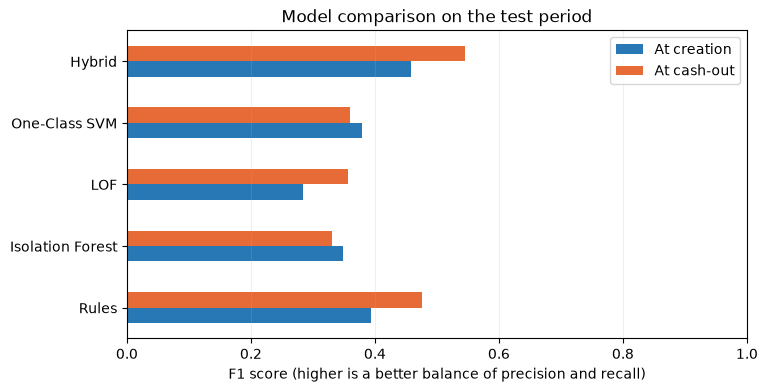

In [4]:
order = ["Rules", "Isolation Forest", "LOF", "One-Class SVM", "Hybrid"]
comparison = results.pivot(index="model", columns="stage", values="f1").reindex(order)
comparison.columns = ["At creation", "At cash-out"]
fig, ax = plt.subplots(figsize=(8,4))
comparison.plot.barh(ax=ax, color=["#2878B5", "#E66B37"])
ax.set(xlabel="F1 score (higher is a better balance of precision and recall)", ylabel="", xlim=(0,1), title="Model comparison on the test period")
ax.grid(axis="x", alpha=.2)
save_figure(fig, FIGURES, "model_f1")
plt.show()

## Which scenarios were flagged?
For scam scenarios the rate is recall. For legitimate episodes it is a false-alarm rate. The group count matters: a high percentage in a small group may create fewer alerts than a small percentage in a large group.

,stage,scenario_type,n,flagged,rate,interpretation
36,A,legit_emergency,268,176,0.6567,False-alarm rate
37,A,legit_new_phone,550,100,0.1818,False-alarm rate
38,A,legit_travel,288,2,0.0069,False-alarm rate
39,A,normal,81679,600,0.0073,False-alarm rate
40,A,scam_classic,269,172,0.6394,Recall
41,A,scam_limit_raise,189,162,0.8571,Recall
42,A,scam_self_send,192,67,0.3490,Recall
43,A,scam_split,358,183,0.5112,Recall
44,A,scam_subtle,154,21,0.1364,Recall
81,B,legit_emergency,264,141,0.5341,False-alarm rate


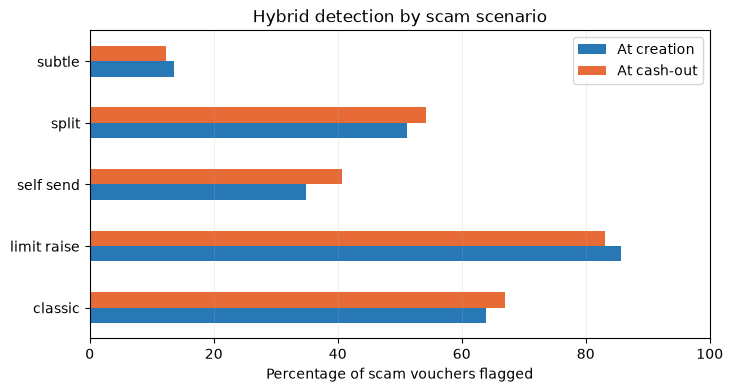

In [5]:
hybrid_scenarios = scenarios[scenarios.model == "Hybrid"]
display(hybrid_scenarios[["stage", "scenario_type", "n", "flagged", "rate", "interpretation"]].round(4))
scam = hybrid_scenarios[hybrid_scenarios.scenario_type.str.startswith("scam_")]
recall = scam.pivot(index="scenario_type", columns="stage", values="rate") * 100
recall.index = recall.index.str.replace("scam_", "").str.replace("_", " ")
recall.columns = ["At creation", "At cash-out"]
fig, ax = plt.subplots(figsize=(8,4))
recall.plot.barh(ax=ax, color=["#2878B5", "#E66B37"])
ax.set(xlabel="Percentage of scam vouchers flagged", ylabel="", xlim=(0,100), title="Hybrid detection by scam scenario")
ax.grid(axis="x", alpha=.2)
save_figure(fig, FIGURES, "scenario_recall")
plt.show()

## Read the result carefully
Creation and cash-out periods use different timestamps and therefore different eligible vouchers. These are separate stage evaluations, not a combined two-stage blocking experiment. The study uses simulated behaviour, and the data had been inspected before this revision. Report the results without claiming a completely unseen development history.

The dashboard now reads the files generated here. Run `streamlit run app/dashboard.py` from the repository root. It displays the stage-specific hybrid, its alert threshold and rule indicators; these indicators explain the rules, not the anomaly model's internal reasoning.